# **Latin Grammar Question Intent Classifier** - Evaluation

Loads the trained model and the tokenized test set, runs evaluation, and produces confusion matrices and a classification report.

## **Import Dependencies**

In [23]:
# import os
# os.environ["WANDB_DISABLED"] = "true"

In [24]:
import os
import sys

import transformers
from transformers import BertTokenizer, BertForSequenceClassification, Trainer, TrainingArguments, AutoModelForSequenceClassification, AutoTokenizer, EarlyStoppingCallback
import datasets
from datasets import load_from_disk

import json
import pandas as pd
import numpy as np
import torch

import sklearn
from sklearn.metrics import accuracy_score, recall_score, precision_score, f1_score, confusion_matrix, classification_report
import seaborn as sns
import matplotlib
import matplotlib.pyplot as plt

In [25]:
%matplotlib inline

In [26]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [27]:
os.chdir('/content/drive/MyDrive/FYP')

In [28]:
# from huggingface_hub import login
# from google.colab import userdata

# login(token=userdata.get('HF_TOKEN'))

In [29]:
print(torch.cuda.is_available())
device = "cuda" if torch.cuda.is_available() else "cpu"
print("Using device:", device)

True
Using device: cuda


In [30]:
print("Python:", sys.version.split()[0])
print("PyTorch:", torch.__version__)
print("Transformers:", transformers.__version__)
print("Datasets:", datasets.__version__)
print("scikit-learn:", sklearn.__version__)
print("pandas:", pd.__version__)
print("NumPy:", np.__version__)
print("Matplotlib:", matplotlib.__version__)
print("seaborn:", sns.__version__)
print("CUDA:", torch.version.cuda)
print("GPU:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "none")

Python: 3.12.13
PyTorch: 2.10.0+cu128
Transformers: 5.0.0
Datasets: 4.0.0
scikit-learn: 1.6.1
pandas: 2.2.2
NumPy: 2.0.2
Matplotlib: 3.10.0
seaborn: 0.13.2
CUDA: 12.8
GPU: Tesla T4


## **Load Test Set**

In [31]:
# Load the tokenized test set and intent_counts
PROCESSED_DIR = "./processed_intent"

test_dataset = load_from_disk(f"{PROCESSED_DIR}/test_dataset")

# Reconstruct intent_counts as a pandas Series with its original frequency-ordered index.
with open(f"{PROCESSED_DIR}/intent_counts.json") as f:
    intent_counts_pairs = json.load(f)

intent_counts = pd.Series(
    [count for _, count in intent_counts_pairs],
    index=[name for name, _ in intent_counts_pairs],
)

print(f"{len(test_dataset)} test examples")

175 test examples


## **Evaluation**

In [32]:
def compute_metrics(eval_pred):
  logits, labels = eval_pred
  preds = logits.argmax(axis=1)
  return {
    "accuracy": accuracy_score(labels, preds),
    "f1": f1_score(labels, preds, average="weighted"),
  }

In [33]:
# load final model and tokenizer
MODEL_PATH = os.path.join('intent_classifier')

model = AutoModelForSequenceClassification.from_pretrained(MODEL_PATH).to(device)
tokenizer = AutoTokenizer.from_pretrained(MODEL_PATH)

trainer = Trainer(
    model=model,
    compute_metrics=compute_metrics
)

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

In [34]:
# evaluate model on test set
trainer.evaluate(test_dataset)

{'eval_loss': 0.07166416943073273,
 'eval_model_preparation_time': 0.0027,
 'eval_accuracy': 1.0,
 'eval_f1': 1.0,
 'eval_runtime': 0.6869,
 'eval_samples_per_second': 254.762,
 'eval_steps_per_second': 32.027}

### Confusion Matrix

In [35]:
# get predictions on test set
pred_output = trainer.predict(test_dataset)
preds = np.argmax(pred_output.predictions, axis=1)
labels = pred_output.label_ids

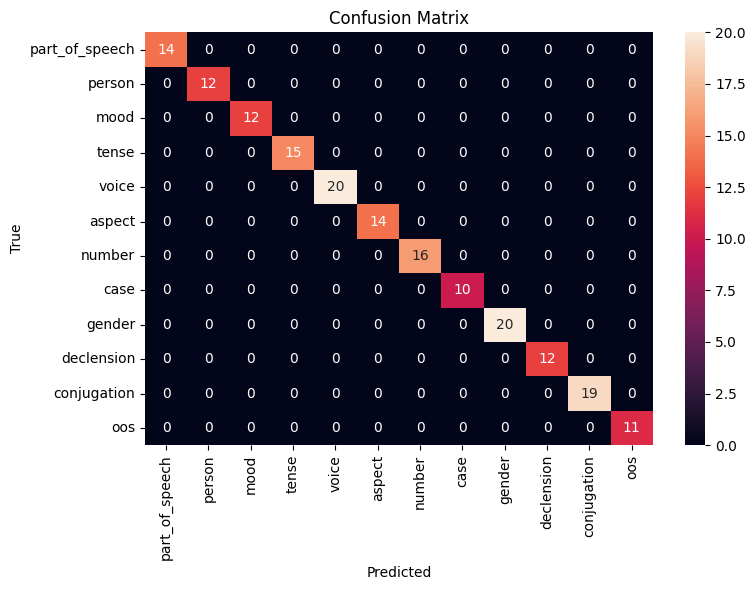

In [36]:
# plot confusion matrix

# create confusion matrix
cm = confusion_matrix(labels, preds)

label_names = intent_counts.index

plt.figure(figsize=(8,6))
sns.heatmap(cm,
            annot=True,
            fmt="d",
            xticklabels=label_names,
            yticklabels=label_names)

plt.xlabel("Predicted")
plt.ylabel("True")
plt.yticks(rotation=0)
plt.title("Confusion Matrix")
plt.tight_layout()
plt.show()

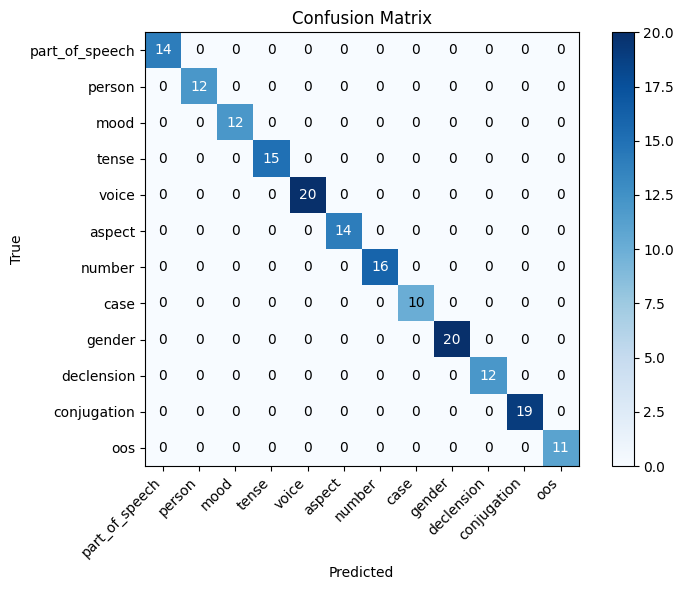

In [37]:
cm = confusion_matrix(labels, preds)

class_names = intent_counts.index

plt.figure(figsize=(8, 6))
plt.imshow(cm, interpolation="nearest", cmap=plt.cm.Blues)
plt.title("Confusion Matrix")
plt.colorbar()

tick_marks = np.arange(len(class_names))
plt.xticks(tick_marks, class_names, rotation=45, ha="right")
plt.yticks(tick_marks, class_names)

plt.xlabel("Predicted")
plt.ylabel("True")

# write numbers
thresh = cm.max() / 2  # for choosing text color
for i in range(cm.shape[0]):
    for j in range(cm.shape[1]):
        plt.text(
            j, i, int(cm[i, j]),
            ha="center", va="center",
            color="white" if cm[i, j] > thresh else "black",
            fontsize=10
        )

plt.tight_layout()
plt.show()

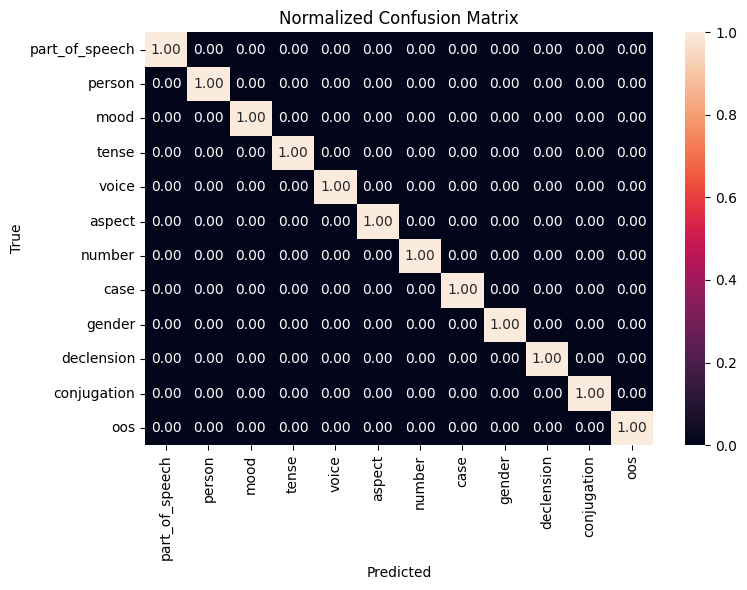

In [38]:
# normalised confusion matrix
cm_norm = confusion_matrix(labels, preds, normalize='true')

plt.figure(figsize=(8,6))
sns.heatmap(cm_norm,
            annot=True,
            fmt=".2f",
            xticklabels=label_names,
            yticklabels=label_names)

plt.xlabel("Predicted")
plt.ylabel("True")
plt.yticks(rotation=0)
plt.title("Normalized Confusion Matrix")
plt.tight_layout()
plt.show()

### Classification Report

In [39]:
# classification report
print(classification_report(labels, preds, target_names=label_names))

                precision    recall  f1-score   support

part_of_speech       1.00      1.00      1.00        14
        person       1.00      1.00      1.00        12
          mood       1.00      1.00      1.00        12
         tense       1.00      1.00      1.00        15
         voice       1.00      1.00      1.00        20
        aspect       1.00      1.00      1.00        14
        number       1.00      1.00      1.00        16
          case       1.00      1.00      1.00        10
        gender       1.00      1.00      1.00        20
    declension       1.00      1.00      1.00        12
   conjugation       1.00      1.00      1.00        19
           oos       1.00      1.00      1.00        11

      accuracy                           1.00       175
     macro avg       1.00      1.00      1.00       175
  weighted avg       1.00      1.00      1.00       175

